# 04 · Vector de fertilidad y cohorte 2025

Estima la probabilidad anual de tener un hijo de cada mujer de 15 a 50 años y la proyecta a
2025-2075 bajo los dos escenarios de la tesis. Además regenera la cohorte de edad 0 de la
población base.

**Pasos**

1. **Ajuste de los nacimientos recientes (edad 0).** Para cada año `T` se compara la cohorte
   de edad 0 en `T` con la de edad 1 en `T+1` (`r_T`), se descuenta el crecimiento genérico de
   la expansión en las edades 1-14 (`g_T`) y se obtiene `f_T = r_T / g_T`. Se aplica un único
   factor, la mediana de los `f_T` (≈ 1,093), al ponderador de los niños de edad 0 y al de sus
   madres. Los microdatos con el ponderador ajustado se guardan para los notebooks 05 y 09.
2. **Panel de mujeres 15-50 (2016-2024):** paridad, maternidad en el año (hijo menor de 0 años,
   con los nietos adjudicados a la hija mayor plausible), pareja, empleo del hogar y tercil de
   ingreso por adulto.
3. **Modelo de la cantidad total de hijos:** MCO, Lasso, Ridge, Random Forest y XGBoost sobre la
   misma partición agrupada por vivienda (tabla *Comparación de especificaciones*). El XGBoost
   se usa en el notebook 07 para completar la descendencia de las generaciones.
4. **Vector de fertilidad:** `logit p = f(X) + g(t) + desvío del estrato(t)`, donde
   - `f(X)` es un XGBoost calibrado (holdout y calibración agrupados por vivienda);
   - `g(t)` es el nivel común, estimado con un GLM individual con *offset* en `f(X)`;
   - el desvío por tramo etario × nivel educativo se encoge con DerSimonian-Laird, se centra
     con pesos poblacionales y se proyecta con saturación τ = 15.
   - **Escenario Base:** `g(t)` satura hacia un piso de TGF de 0,95 (τ_g calibrado con Brent
     sobre la población base). **Escenario Alternativo (rebote):** la trayectoria sigue dos
     logísticas encadenadas (mínimo en el piso, recuperación de +0,25 hijos en 12 años y meseta).
5. **Inyección de la cohorte 2025:** la edad 0 se genera con la misma cascada del motor
   (empleo → pareja → empleo de la pareja → fecundidad → clima educativo, mortalidad infantil y
   sexo con `P_VARON = 0,509`).
6. Figura *Tasa específica de fecundidad por edad y nivel educativo* (introducción).

**Entradas:** `datos/eph/personas_tot.urb_3T_2016.txt` … `_2025.txt`; salidas de los notebooks 01-03.

**Salidas principales:**
- `resultados/intermedios/vectores/fertility_vector.parquet` y `fertility_vector_rebote.parquet`
- `resultados/intermedios/poblacion_base/poblacion_base.csv` (edades 0-100)
- `resultados/intermedios/eph_corregida/*.parquet` y `factores_correccion_edad0.csv`
- `resultados/intermedios/modelos/modelo_children.joblib`, `modelo_motherhood.joblib`, `metadata_modelos.joblib`
- `resultados/intermedios/diagnosticos/` métricas, calibración y *drift* del modelo de fertilidad
- `resultados/figuras/eda_asfr_edad_x_educacion.png`

**Tiempo aproximado:** 6-8 minutos (la búsqueda de hiperparámetros del Random Forest es lo más lento).

In [1]:
import itertools
import os
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import xgboost as xgb
from scipy import stats
from scipy.optimize import brentq
from scipy.special import expit, logit as logit_fn
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import (average_precision_score, brier_score_loss, log_loss, mean_absolute_error,
                             mean_squared_error, r2_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ)
DIR_VEC = Path("resultados/intermedios/vectores")
DIR_POB = Path("resultados/intermedios/poblacion_base")
DIR_EPH_CORR = Path("resultados/intermedios/eph_corregida")
DIR_MOD = Path("resultados/intermedios/modelos")
DIR_DIAG = Path("resultados/intermedios/diagnosticos")
DIR_FIG = Path("resultados/figuras")
for d in (DIR_VEC, DIR_POB, DIR_EPH_CORR, DIR_MOD, DIR_DIAG, DIR_FIG):
    d.mkdir(parents=True, exist_ok=True)

ANIOS_EPH = range(2016, 2026)
ANIO_INICIO_PANEL, ANIO_FIN_PANEL = 2016, 2024
ANIOS_EXCLUIDOS_CALENDARIO = (2020, 2021)
anchor_year = 2025
projection_years = range(2025, 2076)
random_state = 42

N_ESTRATOS_STATUS = 3
status_levels = list(range(1, N_ESTRATOS_STATUS + 1))
MIN_DONANTES_IMPUTACION = 10
SEMILLA_IMPUTACION = 20260905
EDAD_MIN_MATERNIDAD = 15
EDADES_CONTROL_CRECIMIENTO = range(1, 15)

TRAMOS_DRIFT = [(15, 24), (25, 34), (35, 50)]
ESTRATOS_DRIFT = ["tramo_drift", "education_bucket"]
TAU_SATURACION = 15.0
TGF_PISO_OBJETIVO = 0.95
PARITY_MAX_VECTOR = 7
REBOTE_AMPLITUD = 0.25
REBOTE_DURACION = 12.0
REBOTE_FRAC_MESETA = 0.95

N_ITER_RF, N_ITER_XGB, CV_FOLDS_BUSQUEDA = 12, 30, 3
SEMILLA_INYECCION = 2025
P_VARON = 0.509

aglomerado_mapeo = {32: 1, 33: 2, 2: 2, 3: 2, 34: 2, 38: 2, 40: 2, 18: 3, 61: 3, 19: 4, 48: 4,
                    22: 5, 41: 5, 23: 6, 55: 6, 25: 7, 50: 7, 29: 8, 62: 8, 7: 9, 52: 9,
                    8: 10, 44: 10, 12: 11, 43: 11, 15: 12, 47: 12, 10: 13, 51: 13, 26: 14, 57: 14,
                    27: 15, 56: 15, 4: 16, 5: 16, 60: 16, 6: 17, 14: 17, 46: 17, 13: 18, 36: 18,
                    42: 18, 30: 19, 49: 19, 9: 20, 91: 20, 45: 20, 17: 21, 53: 21, 20: 22, 58: 22,
                    31: 23, 93: 24, 54: 24}
PROVINCIA_REGION = {1: 1, 2: 1, 3: 2, 4: 2, 5: 2, 6: 2, 7: 2, 8: 2, 9: 3, 10: 3, 11: 3, 12: 3,
                    13: 4, 14: 4, 15: 4, 16: 5, 17: 5, 18: 5, 19: 5, 20: 6, 21: 6, 22: 6, 23: 6, 24: 6}
EDU_BUCKET = {0: "Bajo (sin instr./primario)", 1: "Bajo (sin instr./primario)", 2: "Bajo (sin instr./primario)",
              3: "Medio (secundario)", 4: "Medio (secundario)", 5: "Alto (superior)", 6: "Alto (superior)"}

## 1 · Ajuste de los nacimientos recientes (edad 0)

In [2]:
EPH_POR_ANIO = {}
for anio in ANIOS_EPH:
    df = pd.read_csv(f'datos/eph/personas_tot.urb_3T_{anio}.txt', sep=';', low_memory=False)
    df.columns = df.columns.str.lower()
    df['pondera'] = pd.to_numeric(df['pondera'], errors='coerce').fillna(0.0).astype(float)
    EPH_POR_ANIO[anio] = df

_EDADES = {y: pd.to_numeric(df['ch06'], errors='coerce').fillna(-9).astype(int).replace(-1, 0)
           for y, df in EPH_POR_ANIO.items()}


def _w(anio, edad):
    return float(EPH_POR_ANIO[anio]['pondera'][_EDADES[anio] == edad].sum())


filas = []
for t in sorted(EPH_POR_ANIO):
    if t + 1 not in EPH_POR_ANIO:
        continue
    r = _w(t + 1, 1) / _w(t, 0)
    g = float(np.median([_w(t + 1, a + 1) / _w(t, a) for a in EDADES_CONTROL_CRECIMIENTO if _w(t, a) > 0]))
    filas.append({'year': t, 'n_muestral_edad0': int((_EDADES[t] == 0).sum()), 'w_edad0_original': _w(t, 0),
                  'w_edad1_en_t1': _w(t + 1, 1), 'ratio_bruto_r': r, 'crecimiento_generico_g': g,
                  'factor_anual': r / g})
tabla_factores_edad0 = pd.DataFrame(filas)
FACTOR_CRONICO_EDAD0 = float(tabla_factores_edad0['factor_anual'].median())
tabla_factores_edad0 = pd.concat([tabla_factores_edad0, pd.DataFrame([{
    'year': 2025, 'n_muestral_edad0': int((_EDADES[2025] == 0).sum()), 'w_edad0_original': _w(2025, 0)}])],
    ignore_index=True)
tabla_factores_edad0['factor_f'] = FACTOR_CRONICO_EDAD0
FACTORES_EDAD0 = dict(zip(tabla_factores_edad0['year'].astype(int), tabla_factores_edad0['factor_f']))
print(f'[edad 0] factor único aplicado (mediana de los factores anuales) = {FACTOR_CRONICO_EDAD0:.4f}')

for y, df in EPH_POR_ANIO.items():
    df['pondera_orig'] = df['pondera'].astype(float).copy()
    df['edad_eph'] = _EDADES[y]
    df['factor_edad0'] = np.where(_EDADES[y] == 0, FACTORES_EDAD0[y], 1.0)
    df['pondera'] = df['pondera_orig'] * df['factor_edad0']

for y, df in EPH_POR_ANIO.items():
    out = df.copy()
    for c in out.columns:
        if out[c].dtype == object:
            out[c] = out[c].astype("string")
    out.to_parquet(DIR_EPH_CORR / f"personas_tot.urb_3T_{y}_pondera_corregida.parquet", index=False)
tabla_factores_edad0.to_csv(DIR_EPH_CORR / "factores_correccion_edad0.csv", index=False)
tabla_factores_edad0

[edad 0] factor único aplicado (mediana de los factores anuales) = 1.0934


,year,n_muestral_edad0,w_edad0_original,w_edad1_en_t1,ratio_bruto_r,crecimiento_generico_g,factor_anual,factor_f
0,2016,1178,531604.0,552678.0,1.039642,1.020040,1.019217,1.093355
1,2017,1074,471137.0,560170.0,1.188975,1.002480,1.186034,1.093355
2,2018,1145,493510.0,507777.0,1.028909,1.018809,1.009914,1.093355
3,2019,991,460968.0,562601.0,1.220477,1.155458,1.056271,1.093355
4,2020,598,396388.0,482604.0,1.217504,1.055047,1.153981,1.093355
5,2021,660,370867.0,422148.0,1.138273,1.041083,1.093355,1.093355
6,2022,668,429816.0,408948.0,0.951449,1.047358,0.908428,1.093355
7,2023,558,344962.0,423161.0,1.226689,1.036958,1.182969,1.093355
8,2024,566,383648.0,477365.0,1.244279,1.058879,1.175090,1.093355
9,2025,419,283030.0,NaN,NaN,NaN,NaN,1.093355


## 2 · Panel de mujeres 15-50

In [3]:
def get_ingreso_adulto(df, col_hogar='hogar_id', col_edad='ch06'):
    itf = pd.to_numeric(df['itf'].astype(str).str.replace(',', '.', regex=False), errors='coerce')
    adultos = df.groupby(col_hogar)[col_edad].transform(lambda s: (s >= 18).sum()).clip(lower=1)
    return itf / adultos


def get_weighted_quantiles(df, value_col, weight_col, k=N_ESTRATOS_STATUS):
    valid = df[value_col].notna() & df[weight_col].notna() & (df[weight_col] > 0)
    df_valid = df[valid].sort_values(value_col, kind='mergesort')
    cum = df_valid[weight_col].cumsum()
    q = pd.cut(cum / cum.iloc[-1], bins=np.linspace(0, 1, k + 1),
               labels=range(1, k + 1), include_lowest=True)
    return q.astype('Int64').reindex(df.index)


def imputar_status(df, seed=SEMILLA_IMPUTACION, k=N_ESTRATOS_STATUS, min_donantes=MIN_DONANTES_IMPUTACION):
    rng = np.random.default_rng(seed)
    st = pd.to_numeric(df['status'], errors='coerce').to_numpy(dtype=float)
    w = pd.to_numeric(df['pondih'], errors='coerce').fillna(0.0).to_numpy(dtype=float)
    for keys in [['education', 'sex', 'clima_educativo', 'provincia'], ['education', 'sex'], None]:
        if not np.isnan(st).any():
            break
        grupos = ({None: np.arange(len(df))} if keys is None
                  else df.groupby(keys, dropna=False, observed=True).indices)
        for pos in grupos.values():
            pos = np.asarray(pos)
            falta = np.isnan(st[pos])
            if not falta.any():
                continue
            don = pos[~falta]
            if len(don) < min_donantes:
                continue
            pw = w[don]
            if not np.isfinite(pw).all() or pw.sum() <= 0:
                pw = np.ones(len(don))
            st[pos[falta]] = rng.choice(st[don], size=int(falta.sum()), replace=True, p=pw / pw.sum())
    resto = np.isnan(st)
    if resto.any():
        st[resto] = rng.integers(1, k + 1, size=int(resto.sum()))
    return pd.Series(st, index=df.index).round().astype(int)


def get_ed_years(df):
    nivel, finalizado, aprobado, educacion = df['ch12'], df['ch13'], df['ch14'], df['education']
    primaria, egb, secundaria, terciario, universidad, posgrado = 6, 9, 12, 14, 16, 18
    aprobado_valido = aprobado.notna() & ~aprobado.isin([98, 99])
    aprobado_safe = aprobado.fillna(0)
    fin1 = finalizado == 1
    val1 = pd.Series(0.0, index=df.index)
    val2 = np.select([fin1, aprobado_valido, educacion == 2],
                     [primaria, np.minimum(aprobado_safe, primaria - 0.5), primaria], default=primaria / 2)
    val3 = np.select([fin1, aprobado_valido, educacion == 2],
                     [egb, np.minimum(aprobado_safe, egb - 0.5), primaria], default=egb / 2)
    val4 = np.select([fin1, aprobado_valido, educacion == 4],
                     [secundaria, np.minimum(primaria + aprobado_safe, secundaria - 0.5), secundaria],
                     default=primaria + 3)
    val5 = np.select([fin1, aprobado_valido, educacion == 4],
                     [secundaria, np.minimum(egb + aprobado_safe, secundaria - 0.5), secundaria],
                     default=egb + 1.5)
    val6 = np.select([fin1, aprobado_valido, educacion == 6],
                     [terciario, np.minimum(secundaria + aprobado_safe, terciario - 0.5), terciario],
                     default=secundaria + 1)
    val7 = np.select([fin1, aprobado_valido, educacion == 6],
                     [universidad, np.minimum(secundaria + aprobado_safe, universidad - 0.5), universidad],
                     default=secundaria + 2.5)
    val8 = np.select([fin1, aprobado_valido],
                     [posgrado, np.minimum(universidad + aprobado_safe, posgrado - 0.5)], default=universidad + 1)
    val9 = np.select([educacion == i for i in range(1, 7)],
                     [primaria / 2, primaria, primaria + 3, secundaria, secundaria + 2, universidad], default=0.0)
    condiciones = [nivel == 1, nivel == 2, nivel == 3, nivel == 4, nivel == 5, nivel == 6, nivel == 7,
                   nivel == 8, nivel.isin([9, 99]) | nivel.isna()]
    return np.select(condiciones, [val1, val2, val3, val4, val5, val6, val7, val8, val9], default=0.0)


def assign_cedu(average_years):
    return pd.cut(average_years, bins=[-np.inf, 7, 11, 14, 16, np.inf], labels=[0, 1, 2, 3, 4], right=False)


def asignar_nietos_a_hijas(df, edad_col):
    idx = df.index
    vacio_n, vacio_age, vacio_m = pd.Series(0.0, index=idx), pd.Series(99.0, index=idx), pd.Series(0, index=idx)
    nietos = (df.loc[df["ch03"] == 5, ["hogar_id", edad_col]].rename(columns={edad_col: "edad_nieto"})
              .reset_index().rename(columns={"index": "idx_nieto"}))
    hijas = (df.loc[(df["ch03"] == 3) & (df["sex"] == 1) & (df[edad_col].between(15, 50)), ["hogar_id", edad_col]]
             .rename(columns={edad_col: "edad_hija"}).reset_index().rename(columns={"index": "idx_hija"}))
    if nietos.empty or hijas.empty:
        return vacio_n, vacio_age, vacio_m
    pares = nietos.merge(hijas, on="hogar_id", how="inner")
    pares = pares[pares["edad_hija"] >= pares["edad_nieto"] + EDAD_MIN_MATERNIDAD]
    if pares.empty:
        return vacio_n, vacio_age, vacio_m
    pares = pares.sort_values(["idx_nieto", "edad_hija", "idx_hija"], ascending=[True, False, True])
    adjudicado = pares.drop_duplicates(subset="idx_nieto", keep="first")
    n_asig = adjudicado.groupby("idx_hija").size()
    min_age = adjudicado.groupby("idx_hija")["edad_nieto"].min()
    nietos_asignados = pd.Series(idx.map(n_asig), index=idx).astype(float).fillna(0.0)
    min_nieto_asig = pd.Series(idx.map(min_age), index=idx).astype(float).fillna(99.0)
    return nietos_asignados, min_nieto_asig, (min_nieto_asig == 0).astype(int)

In [4]:
people_lists = []
for anio, df in EPH_POR_ANIO.items():
    df = df.copy()
    df["ch06"] = df["ch06"].astype(int).replace(-1, 0)
    df["year"] = df["ano4"].astype(int)
    df["education"] = df["nivel_ed"].astype(int).replace(7, 0)
    df["sex"] = df["ch04"].map({2: 1, 1: 0})
    for c in ["ch12", "ch13", "ch14"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df["provincia"] = df["aglomerado"].map(aglomerado_mapeo).fillna(0).astype(int)
    df["hogar_id"] = df["codusu"] + "_" + df["nro_hogar"].astype(str) + "_" + df["ano4"].astype(str)
    df = df.merge(df.groupby("hogar_id").size().reset_index(name="hh_size"), on="hogar_id", how="left")

    df["ed_years"] = get_ed_years(df)
    _ad = df[df["ch06"] >= 18].groupby("hogar_id")["ed_years"].mean().rename("average_years")
    df = df.merge(_ad, on="hogar_id", how="left")
    df["clima_educativo"] = assign_cedu(df["average_years"]).astype("float").fillna(0).astype(int)
    df["ipcf"] = pd.to_numeric(df["ipcf"], errors="coerce")
    df["ingreso_adulto"] = get_ingreso_adulto(df, col_edad="ch06")
    df["status"] = get_weighted_quantiles(df, "ingreso_adulto", "pondih")
    df["status"] = imputar_status(df)

    df["work"] = (df["estado"] == 1).astype(int)
    df["couple"] = df["ch07"].isin([1, 2]).astype(int)
    df["ch08"] = pd.to_numeric(df["ch08"], errors="coerce")
    df["insurance"] = df["ch08"].isin([1, 2, 12, 13, 23, 123]).astype(int)
    df["pp07h"] = pd.to_numeric(df["pp07h"], errors="coerce")
    df["formality"] = (df["pp07h"] == 1).astype(int)

    jefes = df[df["ch03"] == 1][["hogar_id", "work"]].rename(columns={"work": "j_work"})
    conyuges = df[df["ch03"] == 2][["hogar_id", "work"]].rename(columns={"work": "c_work"})
    df = df.merge(pd.merge(jefes, conyuges, on="hogar_id", how="outer"), on="hogar_id", how="left")
    hijos_jefe = (df[df["ch03"] == 3].groupby("hogar_id")
                  .agg(children_jefe=("ch06", "count"), min_child_age_jefe=("ch06", "min")).reset_index())
    df = df.merge(hijos_jefe, on="hogar_id", how="left")
    df["children_jefe"] = df["children_jefe"].fillna(0)
    nietos_asig, min_nieto_asig, _ = asignar_nietos_a_hijas(df, edad_col="ch06")

    mujeres = df[(df["sex"] == 1) & (df["ch06"].between(15, 50))].copy()
    cond_jefa = mujeres["ch03"].isin([1, 2])
    cond_hija = mujeres["ch03"] == 3
    mujeres["target_children"] = np.where(cond_jefa, mujeres["children_jefe"],
                                          np.where(cond_hija, nietos_asig.loc[mujeres.index], 0))
    mujeres["youngest_age"] = np.where(cond_jefa, mujeres["min_child_age_jefe"],
                                       np.where(cond_hija, min_nieto_asig.loc[mujeres.index], 99))
    mujeres["youngest_age"] = mujeres["youngest_age"].fillna(99)
    mujeres["target_motherhood"] = (mujeres["youngest_age"] == 0).astype(int)
    mujeres["parity"] = (mujeres["target_children"] - mujeres["target_motherhood"]).clip(lower=0)
    mujeres["pondera"] = mujeres["pondera"].where(mujeres["target_motherhood"] != 1,
                                                  mujeres["pondera"] * FACTORES_EDAD0[anio])
    mujeres["s_work"] = np.where(mujeres["ch03"] == 1, mujeres["c_work"],
                                 np.where(mujeres["ch03"] == 2, mujeres["j_work"], np.nan))
    mujeres["s_work"] = mujeres["s_work"].fillna(0)
    mujeres["hh_work"] = np.maximum(mujeres["work"], mujeres["s_work"])
    mujeres = mujeres.rename(columns={"ch06": "age"})
    people_lists.append(mujeres[["codusu", "year", "age", "sex", "provincia", "education", "status", "pondera",
                                 "hh_work", "couple", "insurance", "formality", "parity",
                                 "target_children", "target_motherhood"]])

people = pd.concat(people_lists, ignore_index=True)
people['region'] = people['provincia'].map(PROVINCIA_REGION)
for s in status_levels:
    people[f"status{s}"] = (people["status"] == s).astype(int)
print(f"[panel] {len(people):,} mujeres de 15 a 50 años, {people['year'].min()}-{people['year'].max()}")

[panel] 213,914 mujeres de 15 a 50 años, 2016-2025


## 3 · Modelo de la cantidad total de hijos (comparación de especificaciones)

In [5]:
FEATURES_CHILDREN_NUM = ["year", "age"]
FEATURES_CHILDREN_CAT = ["region", "education", "couple", "hh_work", "insurance", "formality",
                         *[f"status{s}" for s in status_levels]]
FEATURES_CHILDREN = FEATURES_CHILDREN_NUM + FEATURES_CHILDREN_CAT + ["age2"]


def train_children_model(people):
    features_num = FEATURES_CHILDREN_NUM + ["age2"]
    df_fert = people.dropna(subset=FEATURES_CHILDREN_NUM + FEATURES_CHILDREN_CAT + ["target_children", "pondera"]).copy()
    df_fert = df_fert[df_fert["year"].between(ANIO_INICIO_PANEL, ANIO_FIN_PANEL)].copy()
    df_fert["age2"] = df_fert["age"] ** 2

    itr, ite = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=random_state)
                    .split(df_fert, groups=df_fert["codusu"]))
    train_mask = pd.Series(False, index=df_fert.index); train_mask.iloc[itr] = True
    test_mask = pd.Series(False, index=df_fert.index); test_mask.iloc[ite] = True
    X_train, X_test = df_fert.loc[train_mask, FEATURES_CHILDREN], df_fert.loc[test_mask, FEATURES_CHILDREN]
    y_train, y_test = df_fert.loc[train_mask, "target_children"], df_fert.loc[test_mask, "target_children"]
    w_train, w_test = df_fert.loc[train_mask, "pondera"], df_fert.loc[test_mask, "pondera"]
    folds = list(GroupKFold(n_splits=CV_FOLDS_BUSQUEDA).split(X_train, y_train,
                                                              groups=df_fert.loc[train_mask, "codusu"]))

    preprocessor = ColumnTransformer([("num", StandardScaler(), features_num),
                                      ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"),
                                       FEATURES_CHILDREN_CAT)])
    ols = Pipeline([("prep", preprocessor), ("reg", LinearRegression())]).fit(
        X_train, y_train, reg__sample_weight=w_train)
    alphas = np.logspace(-4, 1, 20)
    lasso = GridSearchCV(Pipeline([("prep", preprocessor), ("reg", Lasso(random_state=random_state, max_iter=5000))]),
                         {"reg__alpha": alphas}, cv=folds, scoring="neg_root_mean_squared_error", n_jobs=1
                         ).fit(X_train, y_train, reg__sample_weight=w_train).best_estimator_
    ridge = GridSearchCV(Pipeline([("prep", preprocessor), ("reg", Ridge(random_state=random_state))]),
                         {"reg__alpha": alphas}, cv=folds, scoring="neg_root_mean_squared_error", n_jobs=1
                         ).fit(X_train, y_train, reg__sample_weight=w_train).best_estimator_
    param_dist_rf = {"reg__n_estimators": [200, 300, 400, 600], "reg__max_depth": [8, 12, 16, 24, None],
                     "reg__min_samples_leaf": [5, 10, 25, 50], "reg__min_samples_split": [2, 10, 40],
                     "reg__max_features": ["sqrt", 0.5, 1.0]}
    best_rf = RandomizedSearchCV(
        Pipeline([("prep", preprocessor), ("reg", RandomForestRegressor(random_state=random_state, n_jobs=-1))]),
        param_distributions=param_dist_rf, n_iter=N_ITER_RF, cv=folds, scoring="neg_root_mean_squared_error",
        random_state=random_state, n_jobs=1).fit(X_train, y_train, reg__sample_weight=w_train).best_estimator_
    param_dist_xgb = {"reg__n_estimators": [200, 300, 500, 800, 1200], "reg__max_depth": [3, 4, 5, 6, 8, 10],
                      "reg__learning_rate": [0.01, 0.02, 0.03, 0.05, 0.1], "reg__min_child_weight": [1, 5, 10, 20, 50],
                      "reg__subsample": [0.6, 0.7, 0.8, 0.9, 1.0], "reg__colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1.0],
                      "reg__reg_lambda": [0.5, 1, 5, 10, 50], "reg__reg_alpha": [0, 0.1, 1, 5],
                      "reg__gamma": [0, 0.1, 1]}
    best_xgb = RandomizedSearchCV(
        Pipeline([("prep", preprocessor), ("reg", xgb.XGBRegressor(objective="reg:squarederror", tree_method="hist",
                                                                    random_state=random_state, n_jobs=-1))]),
        param_distributions=param_dist_xgb, n_iter=N_ITER_XGB, cv=folds, scoring="neg_root_mean_squared_error",
        random_state=random_state, n_jobs=1).fit(X_train, y_train, reg__sample_weight=w_train).best_estimator_

    metrics = []
    for name, model in [("MCO", ols), ("Lasso", lasso), ("Ridge", ridge), ("RF", best_rf), ("XGB", best_xgb)]:
        pred = model.predict(X_test)
        metrics.append({"Modelo": name, "R2": r2_score(y_test, pred, sample_weight=w_test),
                        "RMSE": mean_squared_error(y_test, pred, sample_weight=w_test) ** 0.5,
                        "MAE": mean_absolute_error(y_test, pred, sample_weight=w_test), "N_test": int(len(y_test))})
    return pd.DataFrame(metrics), best_xgb


metricas_hijos, modelo_children = train_children_model(people)
metricas_hijos.to_csv(DIR_DIAG / "metricas_hijos.csv", index=False)
metricas_hijos

,Modelo,R2,RMSE,MAE,N_test
0,MCO,0.376024,1.054647,0.766349,48983
1,Lasso,0.376239,1.054466,0.763701,48983
2,Ridge,0.376024,1.054647,0.766348,48983
3,RF,0.402467,1.032058,0.708491,48983
4,XGB,0.404193,1.030566,0.706364,48983


## 4 · Modelo de maternidad f(X)

In [6]:
features_motherhood = ["sex", "provincia", "age", "education", "couple", "hh_work", "parity",
                       *[f"status{s}" for s in status_levels]]
FEATURES_CAT_NATIVAS = ["provincia", "education"]
CATEGORIAS_FIJAS = {"provincia": list(range(1, 25)), "education": list(range(0, 7))}


def a_categoricas(X):
    X = X.copy()
    for c in FEATURES_CAT_NATIVAS:
        X[c] = pd.Categorical(X[c].astype("Int64"), categories=CATEGORIAS_FIJAS[c])
    return X


def assign_tramo_drift(age):
    bins = [t[0] for t in TRAMOS_DRIFT] + [TRAMOS_DRIFT[-1][1] + 1]
    return pd.cut(age, bins=bins, labels=[f"{lo}-{hi}" for lo, hi in TRAMOS_DRIFT],
                  right=False, include_lowest=True)


def weighted_calibration_curve(y_true, y_prob, sample_weight, n_bins=10):
    d = pd.DataFrame({"y": np.asarray(y_true), "p": np.asarray(y_prob), "w": np.asarray(sample_weight)})
    d["bin"] = pd.qcut(d["p"], q=n_bins, duplicates="drop")
    d["wp"], d["wy"] = d["w"] * d["p"], d["w"] * d["y"]
    r = d.groupby("bin", observed=True).agg(w_sum=("w", "sum"), wp_sum=("wp", "sum"), wy_sum=("wy", "sum")).reset_index()
    r["prob_predicha_media"] = r["wp_sum"] / r["w_sum"]
    r["frac_positivos_empirica"] = r["wy_sum"] / r["w_sum"]
    r["peso_total"] = r["w_sum"]
    return r[["prob_predicha_media", "frac_positivos_empirica", "peso_total"]].sort_values("prob_predicha_media")


def train_motherhood_model(people):
    df_moth = people.dropna(subset=features_motherhood + ["target_motherhood", "pondera", "year"]).copy()
    df_moth = df_moth[df_moth["year"].between(ANIO_INICIO_PANEL, ANIO_FIN_PANEL)].copy()
    df_moth["sex"] = 1
    itr, ite = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=random_state)
                    .split(df_moth, groups=df_moth["codusu"]))
    train_mask = pd.Series(False, index=df_moth.index); train_mask.iloc[itr] = True
    test_mask = pd.Series(False, index=df_moth.index); test_mask.iloc[ite] = True
    X_train = a_categoricas(df_moth.loc[train_mask, features_motherhood])
    X_test = a_categoricas(df_moth.loc[test_mask, features_motherhood])
    y_train, y_test = df_moth.loc[train_mask, "target_motherhood"], df_moth.loc[test_mask, "target_motherhood"]
    w_train, w_test = df_moth.loc[train_mask, "pondera"], df_moth.loc[test_mask, "pondera"]
    g_train = df_moth.loc[train_mask, "codusu"]

    scale_pos_weight = w_train[y_train == 0].sum() / w_train[y_train == 1].sum()
    param_dist = {"max_depth": [3, 4, 5, 6], "learning_rate": [0.01, 0.03, 0.05, 0.1],
                  "n_estimators": [200, 400, 600], "subsample": [0.7, 0.8, 1.0],
                  "colsample_bytree": [0.7, 0.8, 1.0], "min_child_weight": [1, 5, 10]}
    base_xgb = xgb.XGBClassifier(objective="binary:logistic", eval_metric="logloss", scale_pos_weight=scale_pos_weight,
                                 random_state=random_state, enable_categorical=True, tree_method="hist")
    busqueda = RandomizedSearchCV(base_xgb, param_distributions=param_dist, n_iter=25, scoring="roc_auc",
                                  cv=GroupKFold(n_splits=3), random_state=random_state, n_jobs=-1)
    busqueda.fit(X_train, y_train, sample_weight=w_train, groups=g_train)
    print(f"[f(X)] mejores hiperparámetros: {busqueda.best_params_}")

    folds = list(GroupKFold(n_splits=5).split(X_train, y_train, groups=g_train))
    estimador = xgb.XGBClassifier(objective="binary:logistic", eval_metric="logloss",
                                  scale_pos_weight=scale_pos_weight, random_state=random_state,
                                  enable_categorical=True, tree_method="hist", **busqueda.best_params_)
    modelo = CalibratedClassifierCV(estimator=estimador, method="isotonic", cv=folds)
    modelo.fit(X_train, y_train, sample_weight=w_train)

    proba = modelo.predict_proba(X_test)[:, 1]
    metricas = pd.DataFrame([{"Modelo": "XGB_calibrado_isotonic", "N_train": int(train_mask.sum()),
                              "N_test": int(test_mask.sum()),
                              "Tasa_base_test": float(np.average(y_test, weights=w_test)),
                              "AUC_ROC": roc_auc_score(y_test, proba, sample_weight=w_test),
                              "AUC_PR": average_precision_score(y_test, proba, sample_weight=w_test),
                              "Brier": brier_score_loss(y_test, proba, sample_weight=w_test),
                              "Log_Loss": log_loss(y_test, proba, sample_weight=w_test)}])
    calibracion = weighted_calibration_curve(y_test, proba, w_test, n_bins=10)
    return modelo, metricas, calibracion, df_moth


modelo_fertility, metricas_maternidad, calibracion_maternidad, df_moth = train_motherhood_model(people)
metricas_maternidad.to_csv(DIR_DIAG / "metricas_maternidad.csv", index=False)
calibracion_maternidad.to_csv(DIR_DIAG / "calibracion_maternidad.csv", index=False)
df_moth["education_bucket"] = df_moth["education"].map(EDU_BUCKET)
df_moth["tramo_drift"] = assign_tramo_drift(df_moth["age"])
metricas_maternidad

[f(X)] mejores hiperparámetros: {'subsample': 0.8, 'n_estimators': 400, 'min_child_weight': 10, 'max_depth': 5, 'learning_rate': 0.01, 'colsample_bytree': 0.7}


,Modelo,N_train,N_test,Tasa_base_test,AUC_ROC,AUC_PR,Brier,Log_Loss
0,XGB_calibrado_isotonic,146035,48983,0.040528,0.808773,0.145427,0.036522,0.147556


## 5 · Nivel g(t), desvíos por estrato y calibración del piso

In [7]:
def _fit_logit_trend(group, anio_centrado=anchor_year):
    if len(group) < 500 or group["year"].nunique() < 3:
        return np.nan, np.nan
    X = sm.add_constant(pd.DataFrame({"t": (group["year"] - anio_centrado).astype(float)}, index=group.index))
    w = group["pondera"].to_numpy(dtype=float)
    modelo = sm.GLM(group["target_motherhood"].to_numpy(dtype=float), X, family=sm.families.Binomial(),
                    offset=group["_offset_fx"].to_numpy(dtype=float), freq_weights=w / w.mean())
    try:
        ajuste = modelo.fit(cov_type="cluster", cov_kwds={"groups": group["codusu"].to_numpy()})
    except Exception:
        return np.nan, np.nan
    return float(ajuste.params["t"]), float(ajuste.bse["t"])


def estimar_g_de_t(modelo_fertility, df_moth):
    d = df_moth[df_moth["year"].between(ANIO_INICIO_PANEL, ANIO_FIN_PANEL)
                & ~df_moth["year"].isin(ANIOS_EXCLUIDOS_CALENDARIO)].copy()
    p_hat = modelo_fertility.predict_proba(a_categoricas(d[features_motherhood]))[:, 1]
    X = sm.add_constant(pd.DataFrame({"t": (d["year"] - anchor_year).astype(float)}, index=d.index))
    w = d["pondera"].to_numpy(dtype=float)
    ajuste = sm.GLM(d["target_motherhood"].to_numpy(dtype=float), X, family=sm.families.Binomial(),
                    offset=logit_fn(np.clip(p_hat, 1e-6, 1 - 1e-6)), freq_weights=w / w.mean()
                    ).fit(cov_type="cluster", cov_kwds={"groups": d["codusu"].to_numpy()})
    return (float(ajuste.params["const"]), float(ajuste.params["t"]),
            float(ajuste.bse["const"]), float(ajuste.bse["t"]))


def compute_secular_drift(modelo_fertility, df_moth, group_col):
    df = df_moth[df_moth["year"].between(ANIO_INICIO_PANEL, ANIO_FIN_PANEL)].copy()
    df = df[~df["year"].isin(ANIOS_EXCLUIDOS_CALENDARIO)]
    cols = list(group_col)
    df = df.dropna(subset=cols)
    p_hat = modelo_fertility.predict_proba(a_categoricas(df[features_motherhood]))[:, 1]
    df["_offset_fx"] = logit_fn(np.clip(p_hat, 1e-6, 1 - 1e-6))
    beta_global, _ = _fit_logit_trend(df)

    rows = []
    for key, g in df.groupby(cols, observed=True):
        beta_g, se_g = _fit_logit_trend(g)
        rows.append({**dict(zip(cols, key)), "n_obs": len(g), "beta_group": beta_g, "se_group": se_g})
    t = pd.DataFrame(rows)
    t["categoria"] = t[cols].astype(str).agg("_".join, axis=1)
    t["beta_global"] = beta_global

    s, v = t["beta_group"].values.astype(float), t["se_group"].values.astype(float) ** 2
    valido = np.isfinite(s) & np.isfinite(v) & (v > 0)
    tau2, mu_re = 0.0, beta_global
    if valido.sum() >= 2:
        s_v, v_v = s[valido], v[valido]
        w = 1.0 / v_v
        Q = (w * (s_v - (w * s_v).sum() / w.sum()) ** 2).sum()
        denom = w.sum() - (w ** 2).sum() / w.sum()
        tau2 = max(0.0, (Q - (len(s_v) - 1)) / denom) if denom > 0 else 0.0
        w_re = 1.0 / (tau2 + v_v)
        mu_re = (w_re * s_v).sum() / w_re.sum()
    peso = np.where(valido, tau2 / (tau2 + np.where(valido, v, 1.0)), 0.0)
    t["tau2"], t["mu_efectos_aleatorios"], t["peso_propio"] = tau2, mu_re, peso
    t["beta_shrunk"] = peso * np.where(valido, s, 0.0) + (1.0 - peso) * mu_re
    w_pop = t["n_obs"].to_numpy(float) / t["n_obs"].sum()
    t["beta_desvio"] = t["beta_shrunk"] - float((w_pop * t["beta_shrunk"].to_numpy(float)).sum())
    t["p_value"] = 2 * (1 - stats.norm.cdf((t["beta_group"] / t["se_group"]).abs()))
    return t


G0, G1, SE_G0, SE_G1 = estimar_g_de_t(modelo_fertility, df_moth)
drift_table = compute_secular_drift(modelo_fertility, df_moth, ESTRATOS_DRIFT)
drift_table.to_csv(DIR_DIAG / "drift_fertilidad.csv", index=False)
print(f"[g(t)] g(2025) = {G0:+.4f} (se {SE_G0:.4f}) | pendiente = {G1:+.5f} (se {SE_G1:.5f})")
print(f"[drift] tau^2 = {drift_table['tau2'].iloc[0]:.3e} | peso propio medio = {100 * drift_table['peso_propio'].mean():.0f}%")

[g(t)] g(2025) = -0.2292 (se 0.0608) | pendiente = -0.05034 (se 0.01021)
[drift] tau^2 = 9.453e-04 | peso propio medio = 47%


In [8]:
def g_de_t(anio, g0, g1, tau_g):
    a = np.asarray(anio, dtype=float)
    dt = np.maximum(a - anchor_year, 0.0)
    return np.where(a <= anchor_year, g0 + g1 * (a - anchor_year), g0 + g1 * tau_g * (1.0 - np.exp(-dt / tau_g)))


def _tgf_sintetica(logit_fx, beta_desvio, n, age, g_valor, factor_sat):
    p = expit(logit_fx + g_valor + beta_desvio * factor_sat)
    num, den = np.bincount(age, weights=n * p), np.bincount(age, weights=n)
    m = den > 0
    return float((num[m] / den[m]).sum())


def calibrar_tau_g(modelo_fertility, drift_table, g0, g1, piso_objetivo=TGF_PISO_OBJETIVO):
    """Resuelve τ_g para que la TGF sintética de largo plazo sobre la población base sea el piso
    declarado. La cascada empleo → pareja → empleo de la pareja se evalúa en su valor esperado."""
    pob = pd.read_csv(DIR_POB / 'poblacion_base_sin_edad0.csv')
    w = pob[(pob['sex'] == 1) & (pob['age'].between(15, 49))].copy()
    w['parity'] = w['children'].clip(upper=PARITY_MAX_VECTOR).astype(int)
    k = ['sex', 'provincia', 'status', 'age', 'education']
    w = w.groupby(k + ['parity'], as_index=False)['n'].sum()
    emp = pd.read_parquet(DIR_VEC / 'employment_vector.parquet', columns=k + [f'prob_work_{anchor_year}'])
    par = pd.read_parquet(DIR_VEC / 'partner_vector.parquet',
                          columns=k + [f'prob_couple_{anchor_year}', f'prob_swork_{anchor_year}'])
    w = w.merge(emp, on=k, how='left').merge(par, on=k, how='left').fillna(0)
    pe, pc, pw = (w[f'prob_work_{anchor_year}'].to_numpy(), w[f'prob_couple_{anchor_year}'].to_numpy(),
                  w[f'prob_swork_{anchor_year}'].to_numpy())
    ramas = [(0, 0, (1 - pe) * (1 - pc)), (0, 1, (1 - pe) * pc * (1 - pw)),
             (1, 1, (1 - pe) * pc * pw), (1, 0, pe * (1 - pc)), (1, 1, pe * pc)]
    W = pd.concat([w[k + ['parity', 'n']].assign(hh_work=hw, couple=cp, n=w['n'].to_numpy() * pr)
                   for hw, cp, pr in ramas], ignore_index=True)
    for s_ in status_levels:
        W[f'status{s_}'] = (W['status'] == s_).astype(int)
    W['prob'] = modelo_fertility.predict_proba(a_categoricas(W[features_motherhood]))[:, 1]
    W['tramo_drift'] = assign_tramo_drift(W['age'])
    W['education_bucket'] = W['education'].map(EDU_BUCKET)
    W = W.merge(drift_table[ESTRATOS_DRIFT + ['beta_desvio']], on=ESTRATOS_DRIFT, how='left')
    W['beta_desvio'] = W['beta_desvio'].fillna(0.0)

    lg = logit_fn(np.clip(W['prob'].to_numpy(), 1e-9, 1 - 1e-9))
    bd, nn, ag = W['beta_desvio'].to_numpy(), W['n'].to_numpy(), W['age'].to_numpy().astype(int)
    tgf_ancla = _tgf_sintetica(lg, bd, nn, ag, g0, 0.0)
    piso = lambda tau: _tgf_sintetica(lg, bd, nn, ag, g0 + g1 * tau, TAU_SATURACION)
    tau = float(brentq(lambda t: piso(t) - piso_objetivo, 0.01, 60.0))
    print(f"[τ_g] TGF sintética 2025 = {tgf_ancla:.4f} | piso {piso_objetivo:.2f} -> τ_g = {tau:.2f}")
    return tau, tgf_ancla


TAU_G, TGF_ANCLA = calibrar_tau_g(modelo_fertility, drift_table, G0, G1)

[τ_g] TGF sintética 2025 = 1.2381 | piso 0.95 -> τ_g = 5.67


In [9]:
def _logistica(t, L, U, k, t0, ascendente):
    t = np.asarray(t, dtype=float)
    return L + (U - L) / (1.0 + np.exp((-1.0 if ascendente else 1.0) * k * (t - t0)))


def _calibrar_logistica(L, U, p1, v1, p2, v2, ascendente):
    z = lambda v: np.log((U - L) / (v - L) - 1.0)
    if ascendente:
        k = (z(v1) - z(v2)) / (p2 - p1)
        return k, p1 + z(v1) / k
    k = (z(v1) - z(v2)) / (p1 - p2)
    return k, p1 - z(v1) / k


REBOTE_PISO = TGF_PISO_OBJETIVO
REBOTE_ANIO_MINIMO = int(round(anchor_year + 3.0 * TAU_G))
REBOTE_TECHO = REBOTE_PISO + REBOTE_AMPLITUD
REBOTE_ANIO_TOPE = int(round(REBOTE_ANIO_MINIMO + REBOTE_DURACION))
_K_DESC, _T0_DESC = _calibrar_logistica(REBOTE_PISO - 0.05, TGF_ANCLA + 0.30, anchor_year, TGF_ANCLA,
                                        REBOTE_ANIO_MINIMO, REBOTE_PISO + 0.01, ascendente=False)
_K_ASC, _T0_ASC = _calibrar_logistica(REBOTE_PISO, REBOTE_TECHO, REBOTE_ANIO_MINIMO + 2,
                                      REBOTE_PISO + 0.02 * REBOTE_AMPLITUD / 0.25, REBOTE_ANIO_TOPE,
                                      REBOTE_PISO + REBOTE_FRAC_MESETA * REBOTE_AMPLITUD, ascendente=True)


def tgf_escenario_rebote(anio):
    """Forma de la trayectoria del Escenario Alternativo: sólo se usa el cociente respecto de 2025."""
    a = np.minimum(np.asarray(anio, dtype=float), REBOTE_ANIO_TOPE)
    desc = _logistica(a, REBOTE_PISO - 0.05, TGF_ANCLA + 0.30, _K_DESC, _T0_DESC, ascendente=False)
    asc = _logistica(a, REBOTE_PISO, REBOTE_TECHO, _K_ASC, _T0_ASC, ascendente=True)
    return np.maximum(desc, asc)


serie = tgf_escenario_rebote(np.arange(anchor_year, 2076))
print(f"[rebote] mínimo {serie.min():.3f} en {anchor_year + int(serie.argmin())}, "
      f"meseta {serie[-1]:.3f} desde {REBOTE_ANIO_TOPE}")

[rebote] mínimo 0.960 en 2042, meseta 1.187 desde 2054


In [10]:
def project_fertility_vector(grid, escenario_rebote=False):
    mask_invalida = (grid["sex"] == 0) | (grid["age"] < 15) | (grid["age"] > 50)
    for s in status_levels:
        grid[f"status{s}"] = (grid["status"] == s).astype(int)
    fv = grid.merge(drift_table[ESTRATOS_DRIFT + ["beta_desvio"]], on=ESTRATOS_DRIFT, how="left")
    fv["beta_desvio"] = fv["beta_desvio"].fillna(0.0)
    logit_fx = logit_fn(np.clip(modelo_fertility.predict_proba(a_categoricas(fv[features_motherhood]))[:, 1],
                                1e-6, 1 - 1e-6))
    beta_desvio = fv["beta_desvio"].values
    g_ancla = float(g_de_t(anchor_year, G0, G1, TAU_G))
    for year in projection_years:
        if escenario_rebote:
            nivel = logit_fx + g_ancla + np.log(float(tgf_escenario_rebote(year)) / float(tgf_escenario_rebote(anchor_year)))
        else:
            nivel = logit_fx + float(g_de_t(year, G0, G1, TAU_G))
        factor_sat = TAU_SATURACION * (1.0 - np.exp(-float(year - anchor_year) / TAU_SATURACION))
        fv[f"prob_{year}"] = np.clip(expit(nivel + beta_desvio * factor_sat), 1e-6, 0.9999)
        fv.loc[mask_invalida, f"prob_{year}"] = 0.0
    return fv.drop(columns=["beta_desvio"])


grid = pd.DataFrame(list(itertools.product([1], range(1, 25), status_levels, range(15, 51), range(0, 7),
                                           [0, 1], [0, 1], range(0, 8))),
                    columns=['sex', 'provincia', 'status', 'age', 'education', 'couple', 'hh_work', 'parity'])
grid["education_bucket"] = grid["education"].map(EDU_BUCKET)
grid["tramo_drift"] = assign_tramo_drift(grid["age"])

fertility_vector = project_fertility_vector(grid)
fertility_vector.to_parquet(DIR_VEC / "fertility_vector.parquet", engine="pyarrow", compression="snappy", index=False)
fertility_vector_rebote = project_fertility_vector(grid, escenario_rebote=True)
assert np.abs(fertility_vector[f"prob_{anchor_year}"].to_numpy()
              - fertility_vector_rebote[f"prob_{anchor_year}"].to_numpy()).max() < 1e-12
fertility_vector_rebote.to_parquet(DIR_VEC / "fertility_vector_rebote.parquet", engine="pyarrow",
                                   compression="snappy", index=False)
del fertility_vector_rebote
print(f"[export] vectores de fertilidad (base y rebote): {len(fertility_vector):,} filas cada uno")

[export] vectores de fertilidad (base y rebote): 580,608 filas cada uno


## 6 · Cohorte de edad 0 de 2025

In [11]:
def _generacion(anio_nac):
    cond = [(1946 <= anio_nac) & (anio_nac <= 1964), (1965 <= anio_nac) & (anio_nac <= 1980),
            (1981 <= anio_nac) & (anio_nac <= 1996), (1997 <= anio_nac) & (anio_nac <= 2012),
            (2013 <= anio_nac) & (anio_nac <= 2025)]
    return int(np.select(cond, [1, 2, 3, 4, 5], default=0))


def inyectar_cohorte_2025(anio=anchor_year, semilla=SEMILLA_INYECCION):
    """Genera los nacimientos de 2025 con la cascada del motor y devuelve la base con edades 0-100
    y la paridad de las madres actualizada."""
    rng = np.random.default_rng(semilla)
    pob = pd.read_csv(DIR_POB / 'poblacion_base_sin_edad0.csv')
    cols_base = list(pob.columns)
    k_merge = ['sex', 'provincia', 'status', 'age', 'education']
    k_fert = k_merge + ['couple', 'hh_work', 'parity']
    cedu_cols = [f'prob_cedu{i}_{anio}' for i in range(5)]
    emp = pd.read_parquet(DIR_VEC / 'employment_vector.parquet', columns=k_merge + [f'prob_work_{anio}'])
    par = pd.read_parquet(DIR_VEC / 'partner_vector.parquet',
                          columns=k_merge + [f'prob_couple_{anio}', f'prob_swork_{anio}'] + cedu_cols)
    fert = pd.read_parquet(DIR_VEC / 'fertility_vector.parquet', columns=k_fert + [f'prob_{anio}'])
    mort = pd.read_parquet(DIR_VEC / 'mortality_vector.parquet', columns=['provincia', 'sex', 'age', f'qx_{anio}'])

    women = pob.loc[(pob['sex'] == 1) & (pob['age'] >= 15) & (pob['age'] < 50) & (pob['n'] > 0)].copy()
    women['parity'] = women['children'].clip(upper=PARITY_MAX_VECTOR).astype(int)
    women = women.merge(emp, on=k_merge, how='left').merge(par, on=k_merge, how='left')
    p_cols = [f'prob_work_{anio}', f'prob_couple_{anio}', f'prob_swork_{anio}'] + cedu_cols
    women[p_cols] = women[p_cols].fillna(0)

    n_tot = women['n'].round().astype(int).to_numpy()
    pe, pc, pw = (women[f'prob_work_{anio}'].to_numpy(), women[f'prob_couple_{anio}'].to_numpy(),
                  women[f'prob_swork_{anio}'].to_numpy())
    n_emp = rng.binomial(n_tot, pe); n_des = n_tot - n_emp
    n_emp_par = rng.binomial(n_emp, pc); n_emp_sol = n_emp - n_emp_par
    n_des_par = rng.binomial(n_des, pc); n_des_sol = n_des - n_des_par
    n_des_par_w = rng.binomial(n_des_par, pw); n_des_par_nw = n_des_par - n_des_par_w
    women = pd.concat([women.assign(hh_work=0, couple=0, n=n_des_sol),
                       women.assign(hh_work=0, couple=1, n=n_des_par_nw),
                       women.assign(hh_work=1, couple=1, n=n_des_par_w),
                       women.assign(hh_work=1, couple=0, n=n_emp_sol),
                       women.assign(hh_work=1, couple=1, n=n_emp_par)], ignore_index=True)
    women = women[women['n'] > 0].copy()

    women = women.merge(fert, on=k_fert, how='left')
    women[f'prob_{anio}'] = women[f'prob_{anio}'].fillna(0)
    women['nac'] = rng.binomial(women['n'].to_numpy(), women[f'prob_{anio}'].to_numpy())
    total_nac = int(women['nac'].sum())

    resto, probs, partes = women['nac'].to_numpy().copy(), women[cedu_cols].to_numpy(), []
    for i in range(5):
        p_i = np.clip(probs[:, i] / np.clip(probs[:, i:].sum(axis=1), 1e-9, None), 0, 1)
        n_i = rng.binomial(resto, p_i)
        resto = resto - n_i
        partes.append(women.assign(clima_educativo_bebe=i, nac=n_i))
    nac_cedu = pd.concat(partes, ignore_index=True)
    nac_cedu = nac_cedu[nac_cedu['nac'] > 0]

    nb = nac_cedu.groupby(['provincia', 'status', 'clima_educativo_bebe'], as_index=False)['nac'].sum()
    nb['n_varones'] = rng.binomial(nb['nac'].to_numpy(), P_VARON)
    nb['n_mujeres'] = nb['nac'] - nb['n_varones']
    v = nb.drop(columns=['nac', 'n_mujeres']).rename(columns={'n_varones': 'nac'}).assign(sex=0)
    f = nb.drop(columns=['nac', 'n_varones']).rename(columns={'n_mujeres': 'nac'}).assign(sex=1)
    nb = pd.concat([v, f], ignore_index=True)
    nb = nb.merge(mort.loc[mort['age'] == 0, ['provincia', 'sex', f'qx_{anio}']], on=['provincia', 'sex'], how='left')
    nb[f'qx_{anio}'] = nb[f'qx_{anio}'].fillna(0)
    nb['n'] = rng.binomial(nb['nac'].to_numpy(), np.clip(1 - nb[f'qx_{anio}'].to_numpy(), 0, 1))

    recien = nb[nb['n'] > 0].copy().rename(columns={'clima_educativo_bebe': 'clima_educativo'})
    recien['age'], recien['children'], recien['education'] = 0, 0, 0
    recien['birth_year'] = anio
    recien['generation'] = _generacion(anio)
    recien['region'] = recien['provincia'].map(PROVINCIA_REGION)
    recien = recien[cols_base]

    id_cols = [c for c in cols_base if c != 'n']
    mov = nac_cedu.groupby(id_cols, as_index=False)['nac'].sum().rename(columns={'nac': 'n_movido'})
    mov = mov[mov['n_movido'] > 0]
    pob = pob.merge(mov, on=id_cols, how='left')
    pob['n_movido'] = pob['n_movido'].fillna(0).astype(int)
    pob['n'] = (pob['n'] - pob['n_movido']).clip(lower=0)
    destino = mov.copy()
    destino['children'] = destino['children'] + 1
    destino = destino.rename(columns={'n_movido': 'n'})
    pob = pd.concat([pob.drop(columns='n_movido'), destino[cols_base], recien], ignore_index=True)
    pob = pob.groupby(id_cols, as_index=False, dropna=False)['n'].sum()
    pob = pob[pob['n'] > 0].reset_index(drop=True)
    print(f'[cohorte 2025] nacidos vivos: {total_nac:,} | sobreviven al cierre del año: {int(recien["n"].sum()):,}')
    return pob


poblacion_base_final = inyectar_cohorte_2025()
assert poblacion_base_final.notna().all().all() and (poblacion_base_final['age'] == 0).any()
poblacion_base_final.to_csv(DIR_POB / 'poblacion_base.csv', index=False)
print(f'[export] poblacion_base.csv -> {len(poblacion_base_final):,} celdas, '
      f'{poblacion_base_final["n"].sum():,} personas')

[cohorte 2025] nacidos vivos: 393,213 | sobreviven al cierre del año: 390,676
[export] poblacion_base.csv -> 57,865 celdas, 43,441,707 personas


## 7 · Figura: tasa específica de fecundidad por edad y nivel educativo (2016-2024)

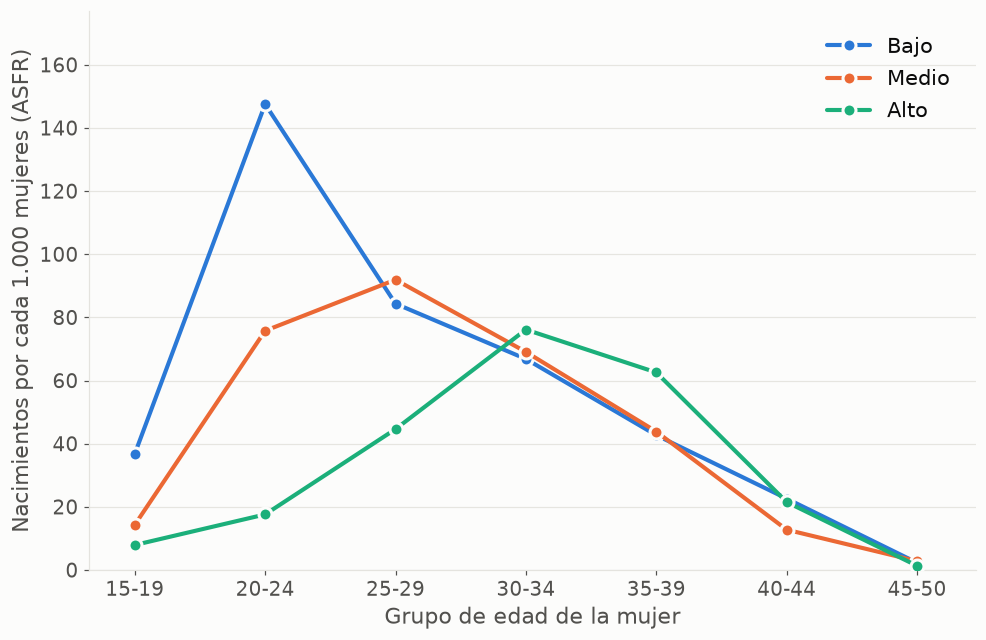

edu,Bajo,Medio,Alto
age_bracket,,,
15-19,36.79,14.31,7.92
20-24,147.53,75.77,17.60
25-29,84.35,91.94,44.62
30-34,66.83,69.06,76.14
35-39,42.70,43.84,62.57
40-44,22.61,12.76,21.51
45-50,2.30,2.81,1.34


In [12]:
BRACKETS = ["15-19", "20-24", "25-29", "30-34", "35-39", "40-44", "45-50"]
ORDEN_EDU = ["Bajo", "Medio", "Alto"]
COL_EDU = {"Bajo": "#2a78d6", "Medio": "#eb6834", "Alto": "#1baf7a"}
INK2, SURF, GRID = "#52514e", "#fcfcfb", "#e4e3de"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "font.size": 10.5,
                     "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": "#0b0b0b",
                     "xtick.color": INK2, "ytick.color": INK2, "axes.titlecolor": "#0b0b0b",
                     "savefig.facecolor": SURF, "figure.dpi": 110})

eda = people[people["year"].between(2016, 2024)].copy()
eda["edu"] = eda["education"].map({0: "Bajo", 1: "Bajo", 2: "Bajo", 3: "Medio", 4: "Medio", 5: "Alto", 6: "Alto"})
eda["age_bracket"] = pd.cut(eda["age"], bins=[15, 20, 25, 30, 35, 40, 45, 51], labels=BRACKETS, right=False)
asfr_edu = (eda.groupby(["age_bracket", "edu"], observed=True)
            .apply(lambda g: 1000 * np.average(g["target_motherhood"], weights=g["pondera"]))
            .rename("asfr").reset_index().pivot(index="age_bracket", columns="edu", values="asfr"))

x = np.arange(len(BRACKETS))
fig, ax = plt.subplots(figsize=(10.4, 6.6))
for e in ORDEN_EDU:
    ax.plot(x, asfr_edu[e].reindex(BRACKETS).values, color=COL_EDU[e], linewidth=2.7, marker="o",
            markersize=8.5, markeredgecolor=SURF, markeredgewidth=2, label=e, zorder=3, solid_capstyle="round")
ax.set_xticks(x); ax.set_xticklabels(BRACKETS)
ax.tick_params(axis="both", labelsize=13)
ax.set_xlabel("Grupo de edad de la mujer", fontsize=14.5)
ax.set_ylabel("Nacimientos por cada 1.000 mujeres (ASFR)", fontsize=14.5)
ax.set_ylim(0, float(np.nanmax(asfr_edu[ORDEN_EDU].values)) * 1.20)
ax.set_xlim(-0.35, len(BRACKETS) - 0.55)
for e in ("top", "right"):
    ax.spines[e].set_visible(False)
ax.grid(axis="y", color=GRID, linewidth=0.8, alpha=0.9); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=14, loc="upper right", borderaxespad=0.8)
fig.savefig(DIR_FIG / "eda_asfr_edad_x_educacion.png", dpi=300, bbox_inches="tight", facecolor=SURF)
plt.show()
asfr_edu.reindex(BRACKETS)[ORDEN_EDU].round(2)

## 8 · Modelos y metadatos

In [13]:
joblib.dump(modelo_fertility, DIR_MOD / "modelo_motherhood.joblib")
joblib.dump(modelo_children, DIR_MOD / "modelo_children.joblib")
joblib.dump({"features_motherhood": features_motherhood, "features_children": FEATURES_CHILDREN,
             "anchor_year": anchor_year, "G0": G0, "G1": G1, "SE_G0": SE_G0, "SE_G1": SE_G1,
             "tau_g": TAU_G, "tgf_piso_objetivo": TGF_PISO_OBJETIVO, "TAU_SATURACION": TAU_SATURACION,
             "escenario_rebote": {"amplitud": REBOTE_AMPLITUD, "duracion": REBOTE_DURACION, "piso": REBOTE_PISO,
                                  "anio_minimo": REBOTE_ANIO_MINIMO, "anio_meseta": REBOTE_ANIO_TOPE}},
            DIR_MOD / "metadata_modelos.joblib")
print("[export] modelos y metadatos guardados")

[export] modelos y metadatos guardados
